<a href="https://colab.research.google.com/github/Nafisazmn/CS-122-Advance-Python/blob/main/Nafisa_Zaman_CS122_HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 122 Spring 2025 HW 6

## Handling Complicated Data

You are tasked to generate a report on students' Math and English performance for SJSU High School. Here are three data files for you to download and upload to Google Drive for use:

- Students Info: https://www.sjsu.edu/people/wendy.lee/docs/CS122/data/sjsu.csv
- Math scores: https://www.sjsu.edu/people/wendy.lee/docs/CS122/data/math_scores.csv
- English scores: https://www.sjsu.edu/people/wendy.lee/docs/CS122/data/english_scores.csv

The data might need some cleaning before you can use them. Missing values should be converted to NaN in the read csv step.


**Lectures to Reference:**

-  [Lecture 10 Data Exploration](https://colab.research.google.com/drive/1XLhwLqUSQNVLY1MXDJ4u3WMZbnmeqgGp?usp=sharing)

-  [Lecture 11 Pandas Data Manipulation](https://colab.research.google.com/drive/1Cn7cn44XnBBKojrr5GzKOM7Qses0Q8w_?usp=sharing)

-  [Lecture 12 Part 1 Introduction to Seaborn](https://colab.research.google.com/drive/1VOhPo0abz4Cl4GgiYV8EGmB4GG1wpCC-?usp=sharing)

-  [Lecture 12 Part 2 Seaborn: Relationship and Categorical plots](https://colab.research.google.com/drive/1gJVvyg0cO-p3S931D3Azgm45AEO1lt_-?usp=sharing)

# Q1. Clean and Merge data
You will need to use Pandas to read the CSV files and load the data into three separate DataFrames. Merge the Math scores and English scores with the DataFrame that contains students' information. You want to retain all the students' information.

**Hint**: You might need to remove lines that are not needed in the csv files using the `read_csv` parameters `skiprows`, `skipfooter`. You might also replace words representing missing values using the parameter `na_values`.

This is how the resulting data frame should look like:

<img src="https://www.sjsu.edu/people/wendy.lee/pics/CS122/students_scores.png" width=500>

In [30]:
# Q1
# Your code here

import pandas as pd

#read and clean student info
students = pd.read_csv(
    "/sjsu.csv",
    skiprows=3,
    skipfooter=1,
    engine="python"
  )
students

#read and clean Math scores
math_scores = pd.read_csv(
    "/math_scores.csv",
    na_values="-"
)
math_scores

#read and clean English scores
english_scores = pd.read_csv(
    "/english_scores.csv",
    skiprows=1,
    na_values = "None"
)
english_scores

#Merge student with math scores
merged_df = pd.merge(
    students,
    math_scores,
    left_on = "#Student_ID",
    right_on ="ID",
    how = "left"
)
merged_df

#Merge result with math scores
merged_df = pd.merge(
    merged_df,
    english_scores,
    left_on = "#Student_ID",
    right_on ="SJSU_ID",
    how = "left"
)

merged_df = merged_df.rename(
    columns={
        "#Student_ID": "Student_ID",
        "Score_x": "Math",
        "Score_y": "English"
    }
)
merged_df

,Student_ID,Name,Age,Gender,Grade,ID,Math,SJSU_ID,English
0,3923,Alice,17,F,11,3923,85.0,3923,87.0
1,6023,Bob,16,M,11,6023,88.0,6023,81.0
2,1262,Charlie,18,M,12,1262,NaN,1262,NaN
3,8325,Camryn,17,F,12,8325,99.0,8325,62.0
4,1352,Diana,17,F,11,1352,90.0,1352,90.0
5,2643,Jocyln,15,F,10,2643,92.0,2643,95.0
6,2532,Andrew,16,M,11,2532,NaN,2532,67.0
7,7235,Hope,15,F,10,7235,89.0,7235,84.0
8,2743,Rogue,18,M,12,2743,NaN,2743,87.0


In [24]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Q2. Create a New Categorical Column in the Dataframe

Here is an example of using values from one column to create categorical values for a new column in the same dataframe

In [25]:
import pandas as pd

# Sample data
data = {
    'Score': [85, 90, 75, 60, 95, 80],
}

# Create DataFrame
df = pd.DataFrame(data)
df

,Score
0,85
1,90
2,75
3,60
4,95
5,80


In [31]:
# Define a function to categorize scores
def categorize_score(score):
    if score >= 90:
        return 'Excellent'
    elif score >= 80:
        return 'Good'
    elif score >= 70:
        return 'Average'
    else:
        return 'Below Average'

# Apply the function to create a new column 'Grade'
df['Grade'] = df['Score'].apply(categorize_score)

# Displaying the DataFrame with the new column
df

,Score,Grade
0,85,Good
1,90,Excellent
2,75,Average
3,60,Below Average
4,95,Excellent
5,80,Good


## Your turn: Create a new column, `Year`, in the merged dataframe and set the category based on the students' grade level:
|Grade level| Year |
|:-:|:-|
|10 | Sophomore|
|11 | Junior |
|12 | Senior |

The resulting dataframe should look like this:

<img src="https://www.sjsu.edu/people/wendy.lee/pics/CS122/students_years.png" width=500>

In [37]:
# Q2

# Your code here . . .

def categorize_grade(grade):
  if grade == 10:
    return "Sophomore"
  elif grade == 11:
    return "Junior"
  else:
    return "Senior"

merged_df["Year"] = merged_df["Grade"].apply(categorize_grade)

merged_df

,Student_ID,Name,Age,Gender,Grade,Math,English,year,Year
0,3923,Alice,17,F,11,85.0,87.0,Junior,Junior
1,6023,Bob,16,M,11,88.0,81.0,Junior,Junior
2,1262,Charlie,18,M,12,NaN,NaN,Senior,Senior
3,8325,Camryn,17,F,12,99.0,62.0,Senior,Senior
4,1352,Diana,17,F,11,90.0,90.0,Junior,Junior
5,2643,Jocyln,15,F,10,92.0,95.0,Sophomore,Sophomore
6,2532,Andrew,16,M,11,NaN,67.0,Junior,Junior
7,7235,Hope,15,F,10,89.0,84.0,Sophomore,Sophomore
8,2743,Rogue,18,M,12,NaN,87.0,Senior,Senior


## Q3. Use `groupby` and `agg` to show the mean score of Math and English group by Year and Gender.

Your results should look like this:  
<img src="https://www.sjsu.edu/people/wendy.lee/pics/CS122/scores_by_gender_and_year.png" width=300>

Here is the <a href='https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html'>Documentation</a> on how to use `groupby` and `agg` with a pandas dataframe

In [39]:
# Q3. Group by Gender and Year and aggregate using mean

# Your code here  . . .

merged_df.groupby(["Gender", "Year"])[["Math", "English"]].agg("mean")

Math  English
Gender Year                    
F      Junior     87.5     88.5
       Senior     99.0     62.0
       Sophomore  90.5     89.5
M      Junior     88.0     74.0
       Senior      NaN     87.0

#Q4 Create a boxplot using Seaborn `catplot` to show the distribution of Math scores and English scores for each Year and use `hue` to separate the boxplot by Gender

Hint: Use the dataframe from Q2 and reshape it into tidy form. Your tidy DataFrame should look like this:

<img src="https://www.sjsu.edu/people/wendy.lee/pics/CS122/students_tidyform.png" width=500>

The boxplot should look like this:

<img src="https://www.sjsu.edu/people/wendy.lee/pics/CS122/students_performance.png" width=800>

In [41]:
# Q4

# Your code here . . .

tidy_df = merged_df.melt(
    id_vars = ["Student_ID", "Name", "Age", "Gender", "Year", "Grade"],
    value_vars = ["Math", "English"],
    var_name = "Subject",
    value_name="Score"
)

tidy_df

,Student_ID,Name,Age,Gender,Year,Grade,Subject,Score
0,3923,Alice,17,F,Junior,11,Math,85.0
1,6023,Bob,16,M,Junior,11,Math,88.0
2,1262,Charlie,18,M,Senior,12,Math,NaN
3,8325,Camryn,17,F,Senior,12,Math,99.0
4,1352,Diana,17,F,Junior,11,Math,90.0
5,2643,Jocyln,15,F,Sophomore,10,Math,92.0
6,2532,Andrew,16,M,Junior,11,Math,NaN
7,7235,Hope,15,F,Sophomore,10,Math,89.0
8,2743,Rogue,18,M,Senior,12,Math,NaN
9,3923,Alice,17,F,Junior,11,English,87.0


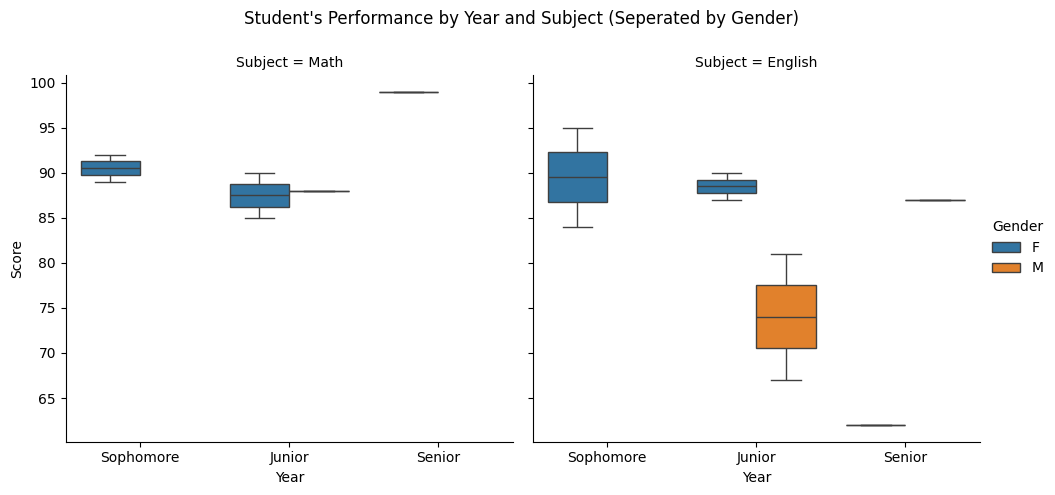

In [44]:
#Boxplot
import seaborn as sns

g = sns.catplot(
    data = tidy_df,
    x = "Year",
    y = "Score",
    hue = "Gender",
    col = "Subject",
    kind = "box",
    order = ["Sophomore", "Junior", "Senior"]
)

g.fig.suptitle("Student's Performance by Year and Subject (Seperated by Gender)")
g.fig.subplots_adjust(top = 0.85)